<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Does a change in fund assets mean the same thing as a change in NAV?

For SPY, reported total net assets should approximately equal **NAV per share × shares outstanding**. A change in either factor can move the fund's asset total. We will reconcile those three reported columns for the first half of 2024, compare their indexed paths, and account for the endpoint difference with explicit arithmetic.

This is a description of a public historical workbook, retrieved live through the real SPDR worker. It does not estimate investor returns, trading activity or net cash flows. NAV changes exclude any separate reinvestment calculation for distributions, and shares outstanding are distinct from exchange trading volume.

## Choose the comparison baseline

`BASE_DATE` accepts **2024-01-02** or **2024-04-01**, two observed dates within the fixed acquisition window **[2024-01-01, 2024-06-30]**, inclusive. These are calendar DATE values without timezone. The endpoint is the last available observation within that window, not a fabricated June 30 value.

Change only **2024-01-02 → 2024-04-01** in the experiment. Predict that the same source rows and final observation remain available while the indexed paths and endpoint changes start from a different baseline. Restart the kernel and Run All after editing.

In [1]:
BASE_DATE = "2024-01-02"  # Experiment: "2024-04-01"; both are observed dates within H1 2024

In [2]:
import hashlib
import os
from datetime import datetime, timezone

import haybarn
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

assert BASE_DATE in {"2024-01-02","2024-04-01"}
os.environ["PLOOMBER_STATS_ENABLED"]="false"
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":125,"text.parse_math":False,"axes.spines.top":False,"axes.spines.right":False})
def prose(text):display(Markdown(text))
def finish(fig):
    fig.text(.01,.01,f"Source: State Street SPY NAV workbook · {BASE_DATE} → {end_date} · retrieved {retrieved_at[:10]} UTC",fontsize=8,color="#555555")
    fig.tight_layout(rect=(0,.06,1,.98));plt.show()
con=haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline


/Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-etf-spdr/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-etf-spdr/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-etf-spdr/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-etf-spdr/notebooks/pyproject.toml.

## Attach the native release and acquire one history file

The literal pinned release downloads and verifies a native worker binary; no Bun installation or worker checkout is required. `nav_history` requests a single [State Street SPY NAV workbook](https://www.ssga.com/library-content/products/fund-data/etfs/us/navhist-us-en-spy.xlsx). The source serves its full history file, then the worker applies the inclusive start/end dates locally. These bounds constrain returned observations, not the workbook's download size.

We materialize the returned rows once so later tables and charts do not refetch the workbook. The UTC acquisition interval is separate from the source's calendar dates. No synthetic response replaces a source failure.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'spdr' AS spdr (
    TYPE vgi,
    LOCATION 'github-auto://Query-farm/vgi-etf-spdr@v0.4.0'
);

,Success


In [4]:
request_started=datetime.now(timezone.utc).isoformat()

In [5]:
%%sql
CREATE TABLE nav_source AS
SELECT * FROM spdr.main.nav_history(
    'SPY',start_date:=DATE '2024-01-01',end_date:=DATE '2024-06-30'
);

,Count


In [6]:
retrieved_at=datetime.now(timezone.utc).isoformat()

## Reconcile dates, units and the asset identity

The [official SPY page](https://www.ssga.com/us/en/intermediary/etfs/state-street-spdr-sp-500-etf-trust-spy) identifies USD as the base currency and defines NAV per share using net assets and shares outstanding. Here NAV is **USD per share**, shares outstanding are **shares**, and the workbook's total net assets are **USD**, not USD millions.

We keep observed dates only. Weekends and holidays do not become zero-valued rows, and the notebook does not claim to verify a complete exchange calendar. Missing, nonpositive or repeated-date observations stop the identity comparison. A one-part-per-million relative tolerance allows published rounding while rejecting a material unit or parsing mismatch.

In [7]:
%%sql diagnostics <<
SELECT count(*) AS observations,count(DISTINCT as_of_date) AS distinct_dates,
       min(as_of_date) AS first_date,max(as_of_date) AS last_date,
       count(*) FILTER (WHERE as_of_date IS NULL OR nav IS NULL OR shares_outstanding IS NULL OR total_net_assets IS NULL) AS incomplete_rows,
       count(*) FILTER (WHERE nav<=0 OR shares_outstanding<=0 OR total_net_assets<=0) AS nonpositive_rows,
       max(abs(total_net_assets-nav*shares_outstanding)/total_net_assets) AS max_relative_identity_error
FROM nav_source;

In [8]:
%%sql history <<
SELECT *,total_net_assets-nav*shares_outstanding AS identity_residual_usd
FROM nav_source ORDER BY as_of_date;

In [9]:
display(diagnostics)
display(history.head())
d=diagnostics.iloc[0]
assert d.observations>1 and d.observations==d.distinct_dates, "Required source must contain unique observed dates."
assert d.incomplete_rows==0 and d.nonpositive_rows==0, "Incomplete/nonpositive data cannot support this identity."
assert d.max_relative_identity_error<1e-6, "Asset identity differs by more than one part per million; inspect units and source."
assert history.as_of_date.min()>=pd.Timestamp("2024-01-01") and history.as_of_date.max()<=pd.Timestamp("2024-06-30")
assert pd.Timestamp(BASE_DATE) in set(history.as_of_date), "The selected baseline must be an observed date."
end_date=pd.Timestamp(d.last_date).date().isoformat()
source_hash=hashlib.sha256(history.to_json(orient="records",date_format="iso").encode()).hexdigest()
prose(f"Retrieved UTC: **{request_started} → {retrieved_at}**. "
      f"The source returned **{int(d.observations)} observations**, from **{pd.Timestamp(d.first_date).date()}** through **{end_date}**. "
      f"The largest identity discrepancy is **{d.max_relative_identity_error*1e6:.4f} parts per million**. "
      f"Full-window fingerprint: `{source_hash}`.")

,observations,distinct_dates,first_date,last_date,incomplete_rows,nonpositive_rows,max_relative_identity_error
0,124,124,2024-01-02,2024-06-28,0,0,1.061768e-09


,as_of_date,nav,shares_outstanding,total_net_assets,identity_residual_usd
0,2024-01-02,472.457482,1.038732e+09,4.907568e+11,35.768005
1,2024-01-03,468.689409,1.036882e+09,4.859757e+11,284.750549
2,2024-01-04,467.142775,1.031232e+09,4.817326e+11,511.488098
3,2024-01-05,467.993065,1.028582e+09,4.813693e+11,23.564514
4,2024-01-08,474.604359,1.023132e+09,4.855830e+11,347.016357


Retrieved UTC: **2026-11-14T06:31:30.355607+00:00 → 2026-11-14T06:31:31.721553+00:00**. The source returned **124 observations**, from **2024-01-02** through **2024-06-28**. The largest identity discrepancy is **0.0011 parts per million**. Full-window fingerprint: `adb4b49c5523c4952cac4ad0cdeb9cf1551492abe0b84ec10640a2bee2fc5cdd`.

## Rebase three distinct quantities to the same starting value

An index of 100 is the selected baseline. We divide each observation by its own baseline value and multiply by 100, making relative changes comparable without mixing USD, shares and USD per share on one raw scale. This index is not a total-return series.

The product identity implies that the asset index is approximately the NAV index multiplied by the shares index, divided by 100. A divergence between the NAV and asset paths therefore need not be an inconsistency.

In [10]:
%%sql
CREATE TABLE indexed AS
WITH baseline AS (SELECT * FROM nav_source WHERE as_of_date=CAST('{{BASE_DATE}}' AS DATE))
SELECT h.as_of_date,100*h.nav/b.nav AS nav_index,
       100*h.shares_outstanding/b.shares_outstanding AS shares_index,
       100*h.total_net_assets/b.total_net_assets AS assets_index
FROM nav_source h CROSS JOIN baseline b
WHERE h.as_of_date>=b.as_of_date;

,Count


In [11]:
%%sql indexed <<
SELECT * FROM indexed ORDER BY as_of_date;

,as_of_date,nav_index,shares_index,assets_index
0,2024-01-02,100.000000,100.000000,100.000000
123,2024-06-28,115.134076,95.725558,110.212737


From **2024-01-02 to 2024-06-28**, NAV per share changed **+15.13%**, shares outstanding **-4.27%**, and total net assets **+10.21%**. Those are changes in three reported quantities, not three estimates of investment performance.

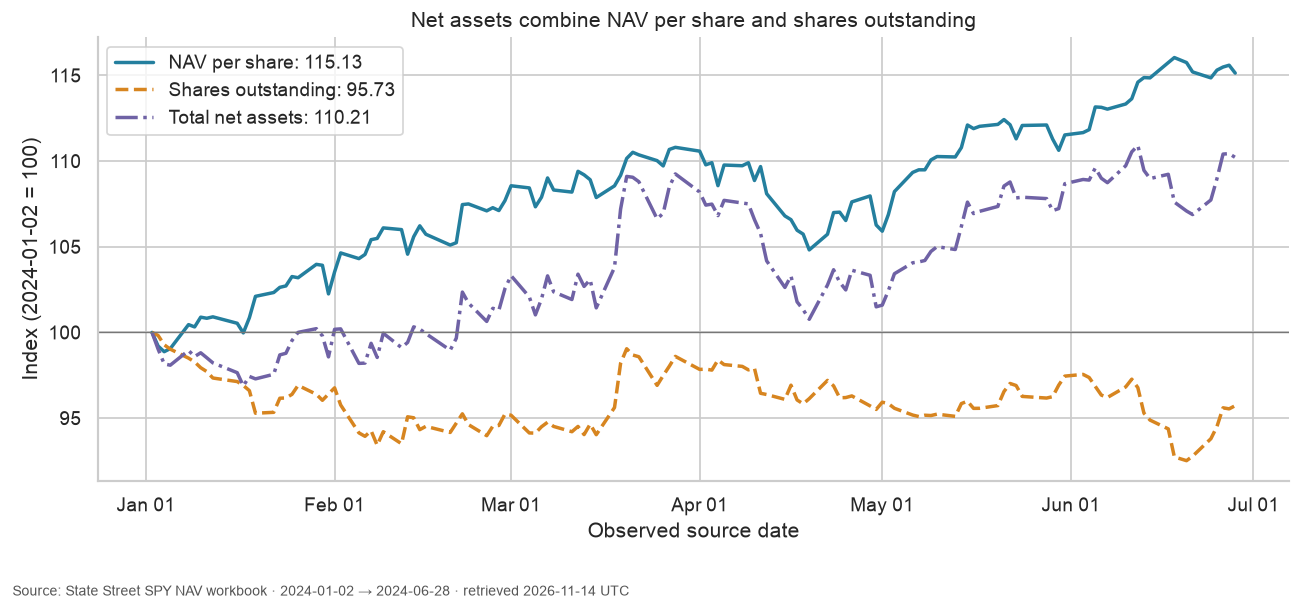

In [12]:
display(indexed.iloc[[0,-1]])
assert np.allclose(indexed.iloc[0][["nav_index","shares_index","assets_index"]].astype(float),100)
assert np.allclose(indexed.assets_index,indexed.nav_index*indexed.shares_index/100,rtol=2e-6)
last=indexed.iloc[-1]
prose(f"From **{BASE_DATE} to {end_date}**, NAV per share changed **{last.nav_index-100:+.2f}%**, "
      f"shares outstanding **{last.shares_index-100:+.2f}%**, and total net assets **{last.assets_index-100:+.2f}%**. "
      "Those are changes in three reported quantities, not three estimates of investment performance.")
fig,ax=plt.subplots(figsize=(10.5,5.0))
for column,label,color,style in [("nav_index","NAV per share","#247f9e","-"),("shares_index","Shares outstanding","#d78520","--"),("assets_index","Total net assets","#6f62a5","-.")]:
    ax.plot(indexed.as_of_date,indexed[column],label=f"{label}: {last[column]:.2f}",color=color,linestyle=style,linewidth=2)
ax.axhline(100,color="#777777",linewidth=.8)
ax.set(xlabel="Observed source date",ylabel=f"Index ({BASE_DATE} = 100)",title="Net assets combine NAV per share and shares outstanding")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"));ax.legend(loc="best");finish(fig)

## Account for the endpoint dollar difference

Write the baseline NAV and shares as **N₀** and **S₀**, and their endpoint changes as **ΔN** and **ΔS**. Expanding the product gives:

**Δ(N × S) = S₀ × ΔN + N₀ × ΔS + ΔN × ΔS**.

The first term changes NAV while holding baseline shares fixed; the second changes shares while holding baseline NAV fixed. The interaction term retains their joint change, so neither order is silently favored. A fourth residual reconciles these terms to the change in the workbook's reported total net assets. These are arithmetic contributions in USD, not estimated cash flows or causal effects.

In [13]:
%%sql components <<
WITH b AS (SELECT * FROM nav_source WHERE as_of_date=CAST('{{BASE_DATE}}' AS DATE)),
     e AS (SELECT * FROM nav_source ORDER BY as_of_date DESC LIMIT 1),
     deltas AS (
       SELECT b.nav AS n0,b.shares_outstanding AS s0,e.nav-b.nav AS dn,
              e.shares_outstanding-b.shares_outstanding AS ds,
              e.total_net_assets-b.total_net_assets AS observed_change
       FROM b CROSS JOIN e
     )
SELECT 1 AS sort_order,'NAV term: baseline shares × ΔNAV' AS component,s0*dn AS contribution_usd FROM deltas
UNION ALL SELECT 2,'Shares term: baseline NAV × Δshares',n0*ds FROM deltas
UNION ALL SELECT 3,'Interaction: ΔNAV × Δshares',dn*ds FROM deltas
UNION ALL SELECT 4,'Reported-assets reconciliation residual',observed_change-(s0*dn+n0*ds+dn*ds) FROM deltas
UNION ALL SELECT 5,'Observed total net assets change',observed_change FROM deltas
ORDER BY sort_order;

,sort_order,component,contribution_usd
0,1,NAV term: baseline shares × ΔNAV,7.427150e+10
1,2,Shares term: baseline NAV × Δshares,-2.097711e+10
2,3,Interaction: ΔNAV × Δshares,-3.174692e+09
3,4,Reported-assets reconciliation residual,1.117772e+02
4,5,Observed total net assets change,5.011970e+10


The first four terms sum to the observed asset change of **USD +50.120 billion**. The reconciliation residual is **USD +111.78** and remains visible in the table, even if it is too small to see at the chart's billion-dollar scale. A shares term is not a cash-flow estimate: endpoint shares omit the timing, prices and in-kind mechanics of intermediate creations or redemptions.

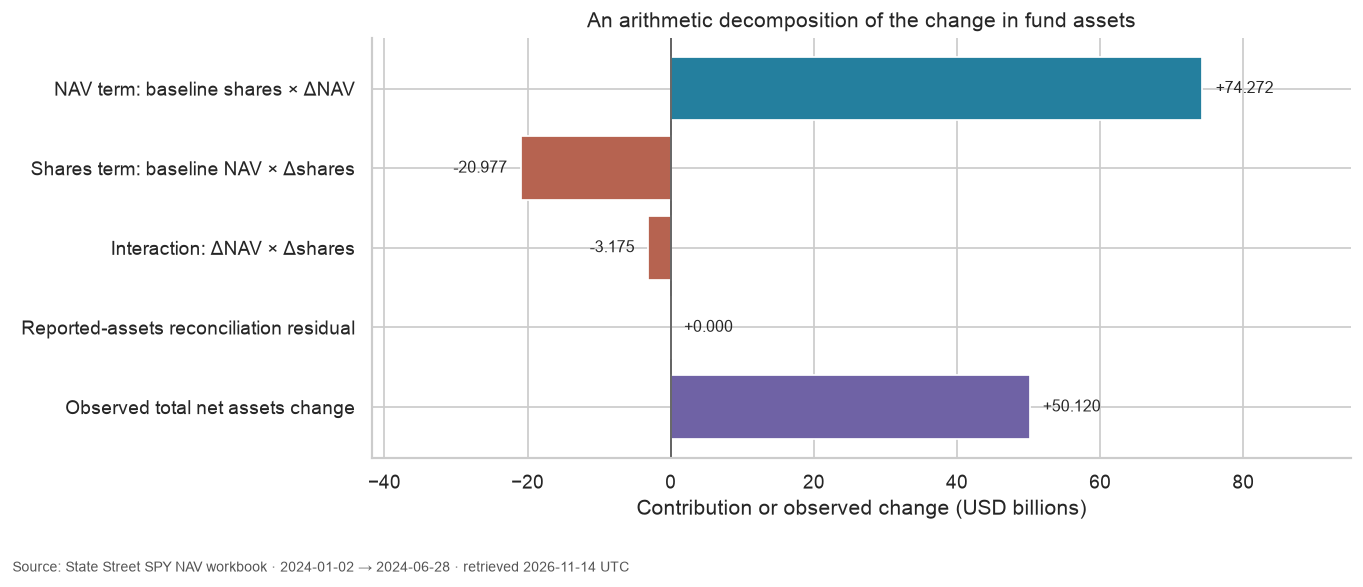

In [14]:
display(components)
assert np.isclose(components.contribution_usd.iloc[:4].sum(),components.contribution_usd.iloc[4],rtol=1e-12,atol=.01)
residual=float(components.contribution_usd.iloc[3])
prose(f"The first four terms sum to the observed asset change of **USD {components.contribution_usd.iloc[4]/1e9:+.3f} billion**. "
      f"The reconciliation residual is **USD {residual:+,.2f}** and remains visible in the table, even if it is too small to see at the chart's billion-dollar scale. "
      "A shares term is not a cash-flow estimate: endpoint shares omit the timing, prices and in-kind mechanics of intermediate creations or redemptions.")
fig,ax=plt.subplots(figsize=(11,4.8))
values=components.contribution_usd/1e9
colors=["#247f9e" if x>=0 else "#b66350" for x in values];colors[-1]="#6f62a5"
ax.barh(components.component,values,color=colors)
span=max(float(values.abs().max()),.001)
ax.set_xlim(min(0,float(values.min()))-.28*span,max(0,float(values.max()))+.28*span)
for i,x in enumerate(values):
    ax.text(x+(.025*span if x>=0 else -.025*span),i,f"{x:+.3f}",ha="left" if x>=0 else "right",va="center",fontsize=9)
ax.axvline(0,color="#555555",linewidth=1);ax.invert_yaxis()
ax.set(xlabel="Contribution or observed change (USD billions)",title="An arithmetic decomposition of the change in fund assets")
finish(fig)

## One change to test

Change only **`BASE_DATE` from `"2024-01-02"` to `"2024-04-01"`** in a separate executed copy. The complete acquisition fingerprint and final source date should remain unchanged, while the shorter comparison period resets the three indices and changes the dollar contributions. Their sum must still reconcile to the reported asset difference. Restore **`"2024-01-02"`** afterward.

Historical workbook values may be corrected, so compare fingerprints before treating the baseline as the only changed input. No exchange calendar was imposed, no gaps were filled and no distribution reinvestment was calculated. The decomposition establishes a numerical relationship; it does not explain why NAV or share counts changed.

In [15]:
con.execute("DETACH spdr")
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and provenance](README.md)